# HOMEWORK 12

In this homework you are going to inspect the GTSDB (German Traffic Sign Detection Benchmark) dataset. The dataset contains images of various classes of traffic signs used in Germany (and the whole EU). The objective of this homework is to go through the steps described below and to implement the necessary code.

At the end, as usual, there will be a couple of questions for you to answer. In addition, the last section of this homework is optional and, if you chose to do it, you'll earn extra point :-)

In [1]:
import os
import cv2
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

### Step 0

Go to the GTSRB dataset official site ([link](https://benchmark.ini.rub.de/gtsrb_dataset.html)) to learn more about the dataset.

### Step 1

Download the dataset ([link](https://www.kaggle.com/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign)) and unzip it.

### Step 2

For this homework, you will be working with the training set. Check out the `Train.csv`, open it and see what it contains. Load the dataset and plot random samples.

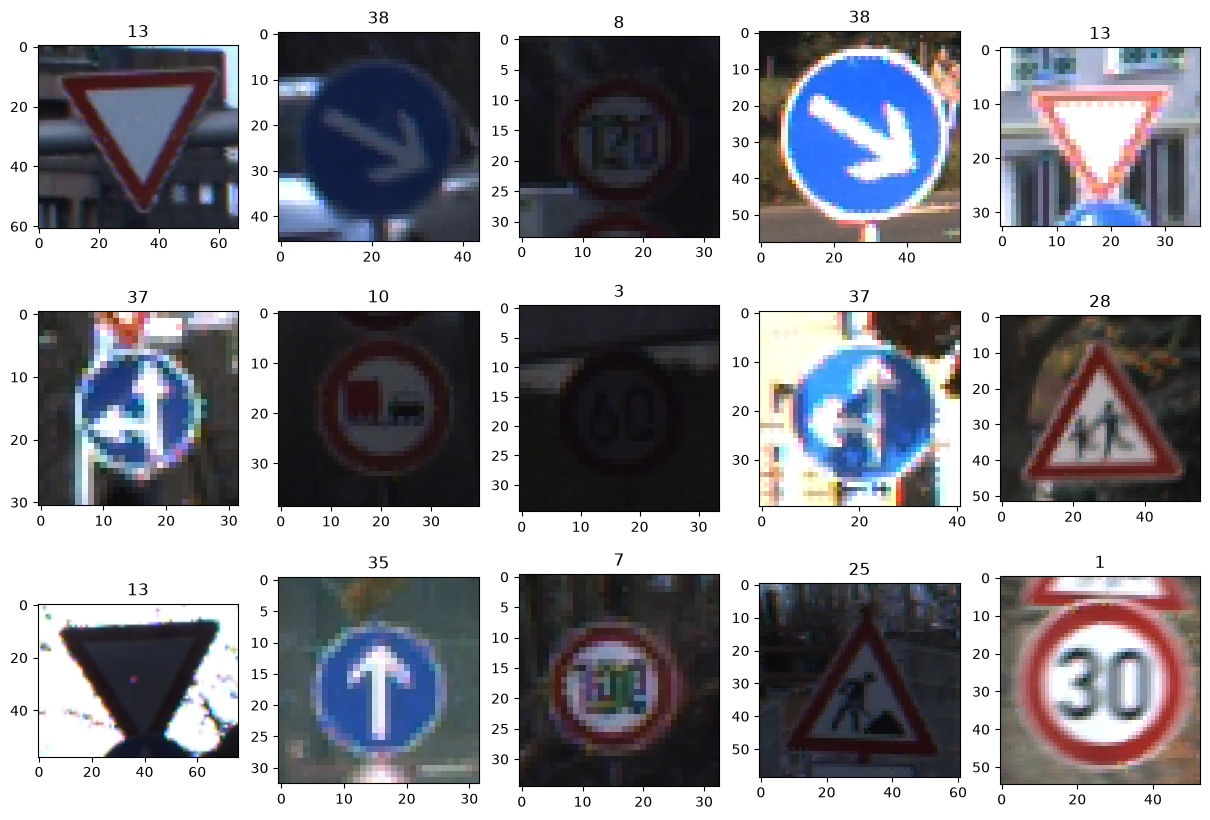

In [2]:
# Load the training labels
root = '../data/GTSRB' # Path to the dataset location, e.g., '/data/janko/dataset/GTSRB'
data = pd.read_csv(os.path.join(root, 'Train.csv'))

# Number of training samples (amount of samples in data)
num_samples = 39209

# Show random data samples
for ii in range(15):
    # Get random index
    idx = np.random.randint(0, num_samples)
    # Load image
    img = cv2.imread(os.path.join(root, data.iloc[idx]['Path']))
    # Convert image to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # Show image
    plt.subplot(3,5,ii+1), plt.imshow(img), plt.title(data.iloc[idx]['ClassId'])

### Step 3

Inspect the dataset by computing and plotting the per-class histogram.

In [3]:
# Extract class identifiers
# Hint: Check the csv 
ids = data['ClassId'].unique()
print(ids)

[20  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42]


Compute the per class histogram. You can use any approach you want (e.g. `numpy`). It's also worth looking at the `Counter` function from the `collections` module ([link](https://docs.python.org/3/library/collections.html#collections.Counter)) ;-)

(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Counts'))

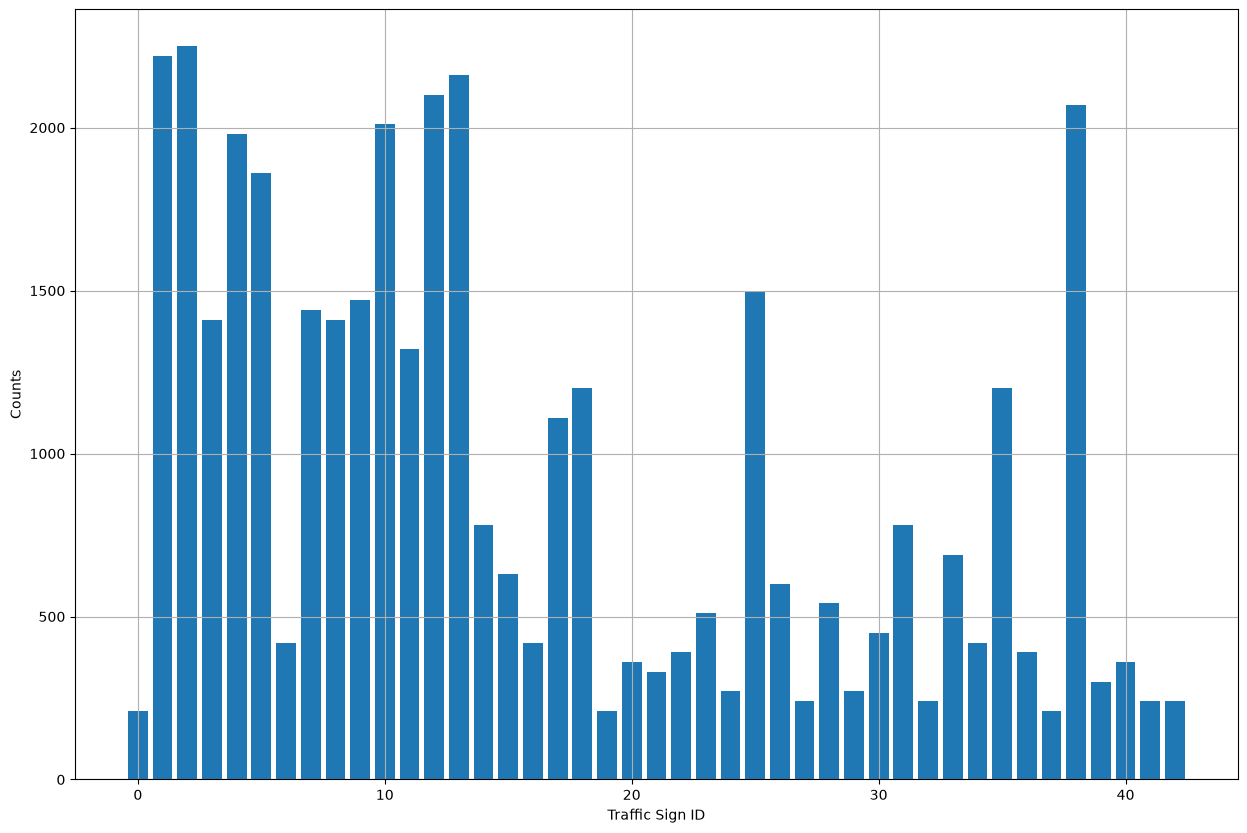

In [4]:
from collections import Counter
#hist = Counter(ids)
#print(hist)
hist = data['ClassId'].value_counts().sort_index()

#plt.bar(hist.keys(), hist.values()), plt.grid(True)
plt.bar(hist.index, hist.values), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Counts')

911.8372093023256


(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Counts'))

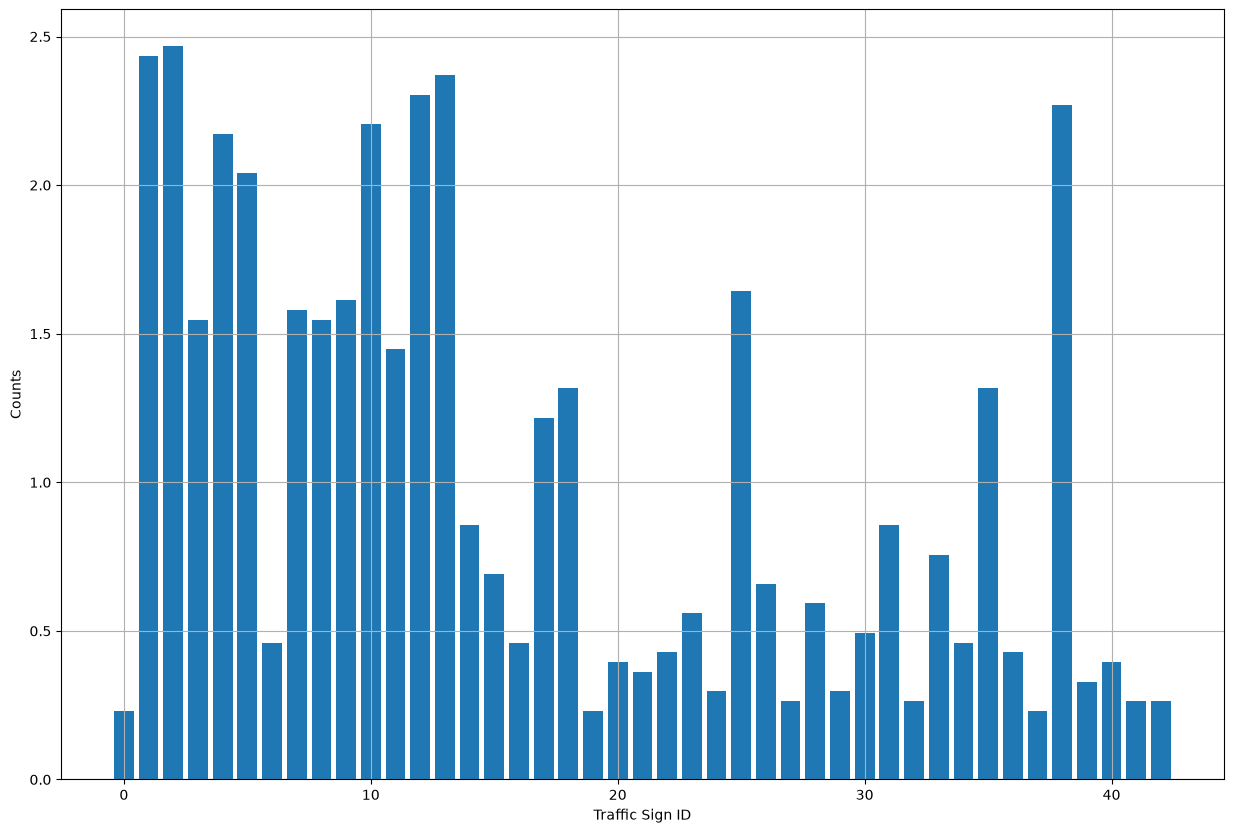

In [5]:
#representation homogenity (expect images from every class have the minimun distance from average value)
average_repr = num_samples / len(ids)
print(average_repr)

plt.bar(hist.index, hist.values/average_repr), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Counts')

### Questions

Please answer the following questions:
* Do you consider the dataset to be balanced? If so, why? If not, why?
  The given dataset is unbalanced because there are classes that overrepresented and underrepresented
* Are there any classes that are (significantly) over-represented or under-represeneted?
  Yes there are classes like 1,2,3 and 38 that are represented more than twice more than the average value for the whole dataset and the classes like 19,20,24 that share very little portion of the dataset.

### Optional

Perform a further analysis on the dataset and draw some conclusion from it.

Hint 1: Unlike MNIST or CIFAR10, this dataset contains images with various spatial resolutions. Is there anything we can tell about the resolution distribution?
Hint 2: What about the brightness distribution? Are there classes there are significantly more bright than others?

(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Counts'))

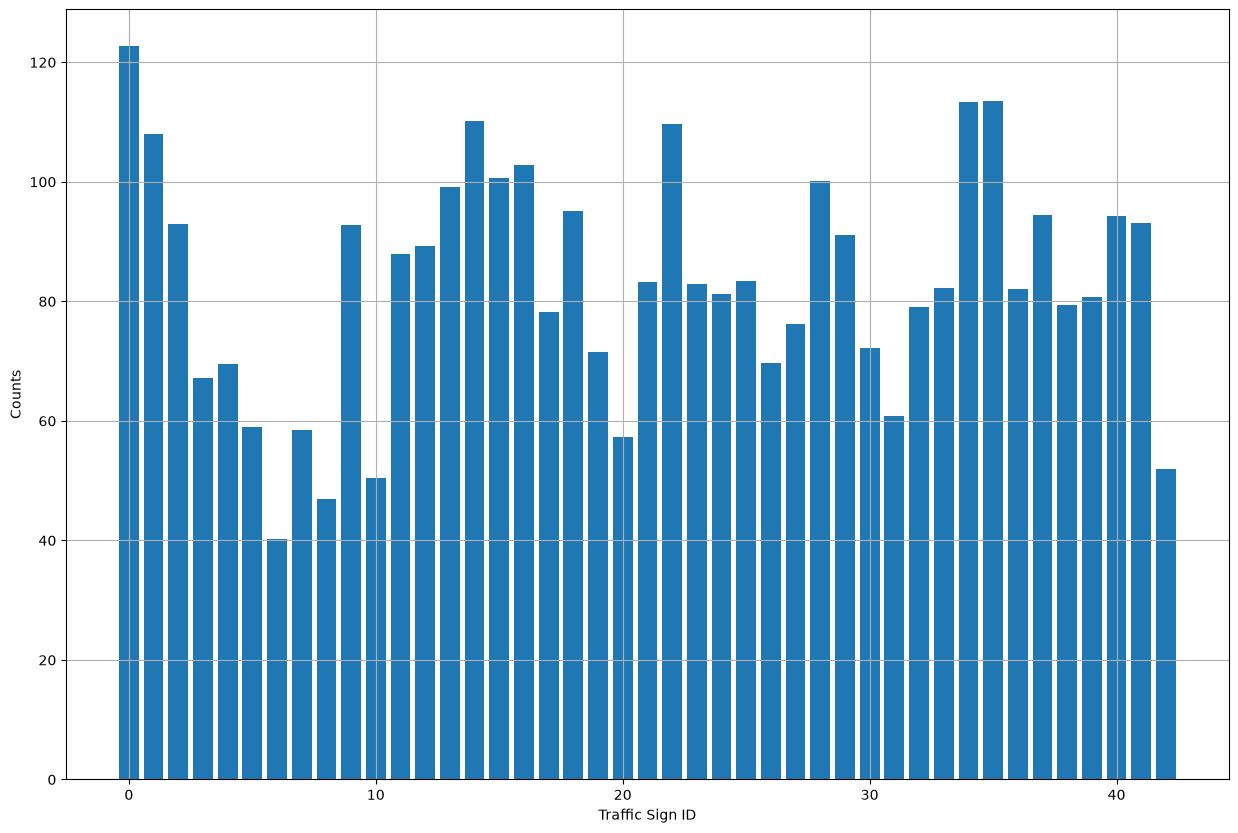

In [19]:
root = "../data/GTSRB/Train"
results = []
for class_id in sorted(os.listdir(root)):
    class_path = os.path.join(root, class_id)
    if not os.path.isdir(class_path):
        continue
    for filename in os.listdir(class_path):
        image_path = os.path.join(class_path, filename)
        img = cv2.imread(image_path)
        if img is None:
            continue
        height, width, _ = img.shape
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        mean_brightness = np.mean(gray)
        results.append({
            "class_id": int(class_id),
            "mean_brightness": mean_brightness,
            "resolution": height*width
        })
        
df = pd.DataFrame(results)
class_means = df.groupby("class_id")["mean_brightness"].mean()

plt.bar(class_means.index, class_means.values), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Counts')

(Text(0.5, 0, 'Traffic Sign ID'), Text(0, 0.5, 'Counts'))

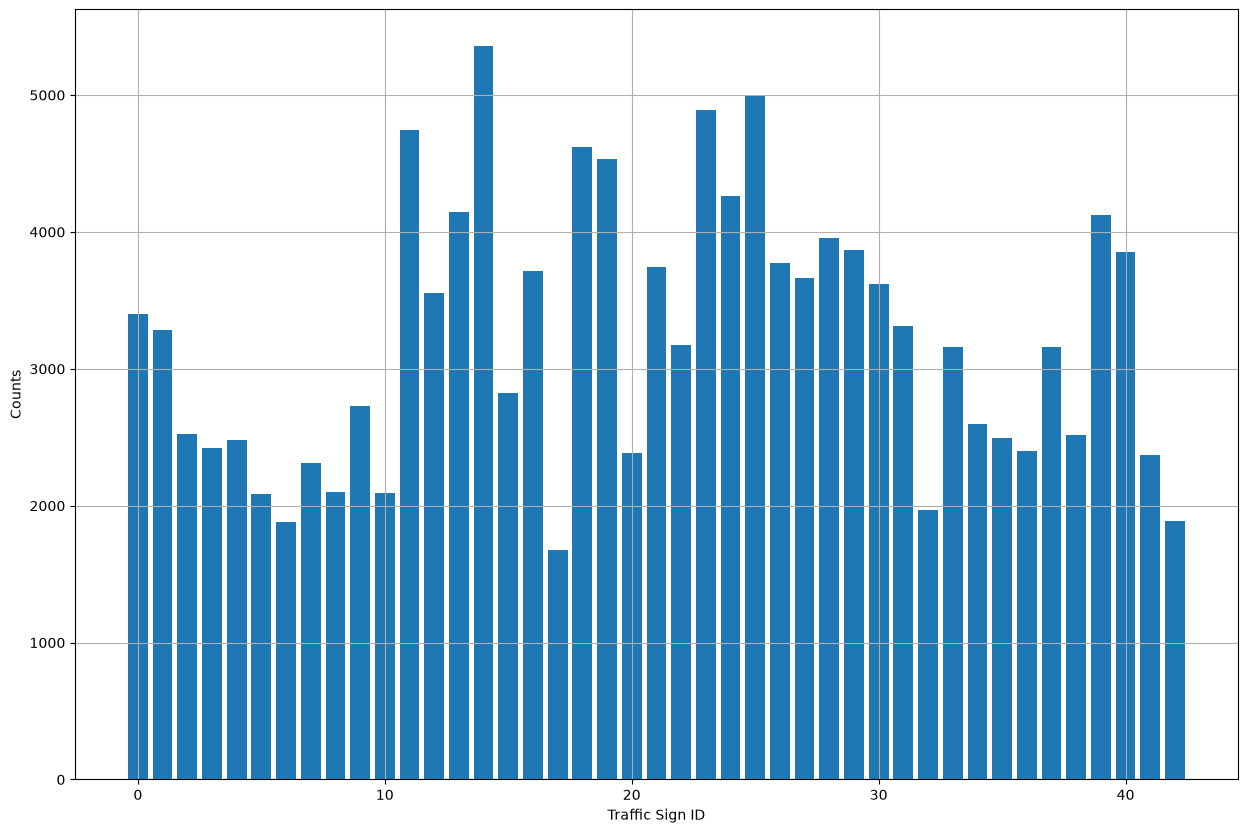

In [20]:
class_resolution = df.groupby("class_id")["resolution"].mean()

plt.bar(class_resolution.index, class_resolution.values), plt.grid(True)
plt.xlabel('Traffic Sign ID'), plt.ylabel('Counts')

The given results of everage brightness per class and average resolution tells that image set is poorly balansed and shoul be normalized by brightness and resolution before feeding it to neuro network to get better results.